# 미션 6_흉부 X-ray 폐렴 분류

흉부 X-ray 이미지 **5,856장**으로 **정상(NORMAL)과 폐렴(PNEUMONIA)** 구분. 직접 설계한 CNN과 ImageNet 사전학습 ResNet18의 **세 가지 전이학습 방식**을 같은 조건에서 비교.

<img src="images/m6_map.png" alt="미션 6 학습 지도: 준비부터 마무리까지 6단계" width="726">

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

**평가 기준**: 폐렴 = 양성(1). **폐렴 환자를 놓치지 않는 재현율**이 최우선, 정상인을 폐렴으로 보는 오진(특이도)도 함께 확인.

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 같은 환자의 사진이 학습 · 검증에 섞이지 않도록 **환자 단위**로 분할하고, 중복 이미지를 정리한다
2. 흑백 X-ray를 사전학습 모델 입력(3채널 · ImageNet 정규화)에 맞추고, 의료 영상에 맞는 증강만 고른다
3. Feature Extraction · Partial · Full Fine-Tuning을 **층별 학습률**로 구현해 같은 조건에서 비교한다
4. 검증 점수와 test 점수의 차이를 확률 분포 · 임계값 · Grad-CAM으로 원인까지 분석한다

## 🧭 활용처

- **의료 영상 판독 보조**: 폐렴 · 결핵 · 골절처럼 놓치면 위험한 질환의 1차 선별 (재현율 우선)
- **적은 데이터의 이미지 분류**: 사전학습 모델 미세 조정으로 수천 장 규모에서도 높은 성능
- **모델 배포 전 점검**: 같은 출처 검증 점수만 믿지 않고 외부 분포에서 성능 저하를 확인하는 절차

## 핵심 결과

- **검증 최고 모델**: ResNet18 Full Fine-Tuning (검증 ROC-AUC 0.9993)
- **test**: ROC-AUC 0.9593, 폐렴 387명 중 **2명만 놓침**(재현율 0.995), 하지만 정상 231명 중 76명을 폐렴으로 판정 → **특이도 0.671**
- **주된 원인**: 검증 ↔ test **데이터 분포 차이**로 보임 (4-3), 검증에서 정한 임계값을 써도 특이도 0.671 → 0.719로 소폭 개선에 그침

### 데이터 구성

- **출처**: Kaggle `paultimothymooney/chest-xray-pneumonia` (`chest_xray/` 폴더)
- **폴더 구조**: `train` · `val` · `test` 아래 `NORMAL` · `PNEUMONIA` (JPEG)
- **목표 변수**: `y` (1 = 폐렴, 0 = 정상)
- **환자 ID**: 파일명에서 추출, `person123_bacteria_45` → `person123`, `IM-0115-0001` → `IM-0115`
- **주의** ⚠️: 공식 `val`이 16장뿐, 같은 환자의 사진 여러 장 → 1 · 2장에서 처리
- **실행 환경**: 첫 실행 때 kagglehub가 데이터를 내려받아 캐시에 저장, 이후 실행은 캐시 사용

---
## 0. 준비

### 0-1. 환경 설정

**한글 요약**

데이터 처리 · 딥러닝 · 평가 라이브러리를 불러오고, 시드 · 이미지 크기 · 학습 장치 지정. 한글 폰트와 그래프 색 통일, 모델마다 같은 출발점을 주는 시드 고정 함수 정의.

**실행 흐름**

1. **입력**: 설치된 라이브러리 · 폰트
2. **처리**: 라이브러리 불러오기 → 시드 · 이미지 크기 · 학습 장치 → 한글 폰트 · 그래프 색 → 난수 고정 함수
3. **저장**: `SEED` · `IMG` · `device` · `seed_all`, 공통 색
4. **출력**: 학습 장치 이름

In [1]:
# 라이브러리 불러오기
import copy  # 최고 성능 시점 가중치를 따로 보관하기 위해
import hashlib  # 파일 바이트 해시로 중복 이미지를 찾기 위해
import re  # 파일명에서 환자 ID를 꺼내기 위해
import time  # 캐시 · 학습 소요 시간을 재기 위해
from pathlib import Path  # 운영체제와 상관없이 경로를 다루기 위해
import kagglehub  # Kaggle 데이터셋을 내려받기 위해
import matplotlib.pyplot as plt  # 그래프를 그리기 위해
import numpy as np  # 배열 계산을 위해
import pandas as pd  # 이미지 목록 · 결과 표를 다루기 위해
import torch  # 텐서 · GPU 연산을 위해
import torch.nn as nn  # 신경망 층 · 손실 함수를 쓰기 위해
import torch.nn.functional as F  # Grad-CAM의 ReLU · 보간을 쓰기 위해
from IPython.display import display  # 셀 중간에 표를 출력하기 위해
from matplotlib import font_manager  # 설치된 한글 폰트를 찾기 위해
from PIL import Image  # 이미지 파일을 읽기 위해
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score, roc_auc_score, roc_curve  # 평가 지표 · 그래프를 위해
from sklearn.model_selection import StratifiedGroupKFold  # 환자 단위로 클래스 비율을 유지해 나누기 위해
from torch.utils.data import DataLoader, Dataset  # 배치 단위로 데이터를 공급하기 위해
from torchvision import models  # 사전학습 ResNet18을 쓰기 위해
from torchvision.transforms import v2  # 학습용 증강을 위해

# 기본 설정
SEED, IMG = 42, 224  # 결과 재현을 위한 시드, ResNet 입력 크기에 맞추기 위해 224
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 있으면 학습을 빠르게 하기 위해
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")  # 학습 장치를 확인하기 위해

# 그래프 스타일
installed = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트를 빠르게 찾기 위해
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 어디서든 한글이 보이도록
    if font in installed:  # 설치된 첫 한글 폰트를 쓰기 위해
        plt.rcParams["font.family"] = font  # 그래프 한글 깨짐을 막기 위해
        break  # 하나만 적용하기 위해
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않도록
BLUE, RED = "#2a78d6", "#d03b3b"  # 모든 그래프에서 정상 · 폐렴을 같은 색으로 보이기 위해

# 난수 고정 함수
def seed_all(seed=SEED):  # 모델마다 같은 출발점에서 학습하기 위해
    """numpy · torch CPU · GPU 난수 고정"""
    np.random.seed(seed)  # numpy 난수를 고정하기 위해
    torch.manual_seed(seed)  # 가중치 초기화 · 증강 난수를 고정하기 위해
    torch.cuda.manual_seed_all(seed)  # GPU 난수도 고정하기 위해

device: cuda | NVIDIA GeForce RTX 3060


**결과 해설**

```
device: cuda            : GPU로 학습 (혼합 정밀도 사용 가능)
NVIDIA GeForce RTX 3060 : 학습 시간은 이 GPU 기준
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| seed_all() | 사용자 정의 함수 | numpy · torch 난수 고정 | `def seed_all(seed=SEED):` |
| cuda.is_available() · cuda.get_device_name() · manual_seed() | torch | GPU 여부 · 이름 · 난수 고정 | `torch.cuda.get_device_name(0)` |
| random.seed() | numpy | numpy 난수 고정 | `np.random.seed(seed)` |
| fontManager.ttflist · rcParams | matplotlib | 폰트 목록 · 전역 설정 | `plt.rcParams["font.family"] = font` |
| print() | Python 내장 함수 | 학습 장치 출력 | `print("device:", device, ...)` |
| import · 조건 표현식 · for · if · break | Python 기본 문법 | 불러오기 · GPU 선택 · 폰트 탐색 | `"cuda" if torch.cuda.is_available() else "cpu"` |

---
## 1. 데이터 점검

### 1-1. 이미지 목록과 환자 ID

**한글 요약**

- 데이터셋을 내려받아 `train` · `val` · `test` × `NORMAL` · `PNEUMONIA` 폴더의 JPEG 경로를 한 표로 정리
- 파일명에서 **환자 ID** 추출 → 같은 환자의 사진이 학습 · 검증에 나뉘는지 확인하기 위한 준비
- 분할 × 클래스별 이미지 수 확인

**실행 흐름**

1. **입력**: kagglehub 캐시의 `chest_xray/` 폴더
2. **처리**: 분할 · 클래스별 경로 수집 → 폐렴 = 1 라벨 → 파일명에서 환자 ID 추출
3. **저장**: `meta` (경로 · 분할 · 라벨 · y · 환자 ID)
4. **출력**: 분할 × 클래스 이미지 수 표

In [2]:
# 이미지 목록
root = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")) / "chest_xray"  # 실행 환경마다 다른 캐시 경로를 받기 위해
records = [{"path": p, "split": split, "label": label}  # 이미지 1장을 표 1행으로 만들기 위해
           for split in ["train", "val", "test"] for label in ["NORMAL", "PNEUMONIA"]  # 분할 3개 × 클래스 2개를 모두 돌기 위해
           for p in sorted((root / split / label).glob("*.jpeg"))]  # 실행마다 같은 순서가 되도록 정렬
meta = pd.DataFrame(records)  # 경로 · 분할 · 라벨을 한 표로 다루기 위해
meta["y"] = (meta["label"] == "PNEUMONIA").astype(int)  # 폐렴을 양성(1)으로 두기 위해

# 환자 ID 추출 함수
def patient_id(name):  # 같은 환자의 사진을 묶기 위해
    """파일명 → 환자 ID (person123_bacteria_45 → person123, IM-0115-0001 · NORMAL2-IM-0115-0001 → IM-0115)"""
    m = re.match(r"(person\d+)_", name)  # 폐렴 파일명 형식을 찾기 위해
    if m:  # 폐렴 형식이면
        return m.group(1)  # personN 부분을 환자 ID로 쓰기 위해
    m = re.search(r"(IM-\d+)", name)  # 정상 파일명 형식을 찾기 위해
    return m.group(1) if m else name  # 두 형식 모두 아니면 파일명 그대로 쓰기 위해

# 환자 ID · 분할별 개수
meta["patient"] = meta["path"].map(lambda p: patient_id(p.stem))  # 확장자를 뺀 파일명에서 환자 ID를 붙이기 위해
pd.crosstab(meta["split"], meta["label"], margins=True, margins_name="합계")  # 분할 × 클래스 이미지 수를 확인하기 위해

label,NORMAL,PNEUMONIA,합계
split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
합계,1583,4273,5856


**결과 해설**

```
전체 5,856장       : train 5,216 · val 16 · test 624
공식 val 16장      : 정상 8 · 폐렴 8 → 1장만 틀려도 정확도 6%p 변동, 검증용으로 부족
train 폐렴 3,875장 : 정상 1,341장의 약 2.9배 → 클래스 불균형
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| patient_id() | 사용자 정의 함수 | 파일명 → 환자 ID | `patient_id(p.stem)` |
| dataset_download() | kagglehub | 내려받기 · 캐시 경로 | `kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")` |
| Path · glob() · stem | pathlib | 경로 · 패턴 파일 · 확장자 뺀 이름 | `(root / split / label).glob("*.jpeg")` |
| match() · search() · group() | re | 처음 · 중간 패턴 · 괄호 부분 | `re.match(r"(person\d+)_", name)` |
| DataFrame() · crosstab() · map() | pandas | 표 · 교차 개수 · 값마다 함수 | `pd.crosstab(meta["split"], meta["label"], margins=True, ...)` |
| 중첩 컴프리헨션 · lambda · r"..." | Python 기본 문법 | 목록 생성 · 한 줄 함수 · 정규식 문자열 | `lambda p: patient_id(p.stem)` |

### 1-2. 환자별 사진 수와 중복 이미지

**한글 요약**

- 학습 · 검증 후보(공식 train + val)에서 **환자 한 명당 사진 수** 확인 → 이미지 단위로 나누면 같은 환자가 양쪽에 섞이는 누수 위험
- 파일 바이트의 MD5 해시로 **완전히 같은 중복 이미지** 탐지, 중복 그룹이 어느 분할에 걸쳐 있는지 확인

<img src="images/m6_patient.png" alt="이미지 단위 분할과 환자 단위 분할 비교" width="837">

**실행 흐름**

1. **입력**: 1-1의 `meta`
2. **처리**: test 제외 이미지를 환자별로 집계 → 이미지별 MD5 해시 → 해시가 같은 행 → 중복 그룹의 분할 구성
3. **저장**: `meta["md5"]` · `dup`
4. **출력**: 환자 수 · 2장 이상 환자 · 최대 장수, 중복 규모 · 분할 구성

In [3]:
# 환자별 사진 수
per_patient = meta[meta["split"] != "test"].groupby("patient").size()  # 학습 · 검증 후보에서 환자 한 명당 사진 수를 보기 위해
print(f"환자 수 {per_patient.size:,}명 · 2장 이상 찍힌 환자 {(per_patient > 1).sum():,}명 · 한 환자 최대 {per_patient.max()}장")  # 누수 위험 규모를 확인하기 위해

# 완전 중복 이미지
meta["md5"] = meta["path"].map(lambda p: hashlib.md5(p.read_bytes()).hexdigest())  # 내용이 같은 파일을 찾기 위해 해시 계산
dup = meta[meta.duplicated("md5", keep=False)].sort_values("md5")  # 해시가 같은 모든 행을 모아 보기 위해
split_mix = dup.groupby("md5")["split"].apply(lambda s: "+".join(sorted(s))).value_counts().to_dict()  # 중복이 분할 사이에 걸치는지 보기 위해
print(f"바이트가 완전히 같은 중복 이미지: {len(dup)}장 ({dup['md5'].nunique()}그룹) → split 구성: {split_mix}")  # 중복 규모와 구성을 확인하기 위해

환자 수 2,650명 · 2장 이상 찍힌 환자 1,250명 · 한 환자 최대 30장


바이트가 완전히 같은 중복 이미지: 62장 (30그룹) → split 구성: {'train+train': 22, 'test+test': 6, 'train+train+train': 2}


**결과 해설**

```
환자 2,650명 중 1,250명이 2장 이상 : 이미지 단위로 나누면 같은 환자가 학습 · 검증에 섞임
한 환자 최대 30장                  : 모델이 환자를 외워 검증 점수가 부풀려질 위험
중복 62장 (30그룹)                 : 모두 같은 분할 안 (train+train · test+test), 분할 사이 중복 없음
```

- **공식 검증셋이 16장뿐** (1장만 틀려도 정확도 6%p 변동) → train + val을 합친 뒤 약 15%를 검증용으로 재분할 (2-1)
- **같은 환자의 사진이 여러 장** → **환자 ID 단위** 분할 (`StratifiedGroupKFold`, 2-1)
- **클래스 불균형** (폐렴 약 3배, 모두 폐렴이라 답해도 정확도 74%) → 손실 함수에 **클래스 가중치** 적용 (2-3)
- **완전히 같은 중복 이미지** 62장 (30그룹) → 그룹마다 한 장만 유지 (2-1)

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| md5() · hexdigest() · read_bytes() | hashlib · pathlib | 파일 내용 해시 · 16진수 · 바이트 읽기 | `hashlib.md5(p.read_bytes()).hexdigest()` |
| groupby() · size() · duplicated() · sort_values() | pandas.DataFrame | 환자별 장수 · 같은 해시 · 정렬 | `meta.duplicated("md5", keep=False)` |
| apply() · value_counts() · to_dict() · nunique() | pandas.Series | 분할 이름 합치기 · 개수 · 그룹 수 | `dup.groupby("md5")["split"].apply(...)` |
| sorted() · len() | Python 내장 함수 | 분할 이름 정렬 · 중복 수 | `"+".join(sorted(s))` |
| str.join() · f-string {:,} | Python 기본 문법 | 이어 붙이기 · 천 단위 쉼표 | `f"{per_patient.size:,}명"` |

---
## 2. 분할 · 전처리

### 2-1. 중복 제거와 환자 단위 재분할

**한글 요약**

- 중복 그룹마다 한 장만 남기고, test는 마지막 평가용으로 분리
- 16장뿐인 공식 val을 train과 합친 뒤 `StratifiedGroupKFold`로 **환자 단위 · 클래스 비율 유지** 분할 (7겹 중 1겹 ≈ 15%를 검증용)
- 학습 · 검증 사이 환자 겹침 0명 검증, 분할별 폐렴 비율 확인

<img src="images/m6_resplit.png" alt="공식 분할에서 환자 단위 재분할까지" width="929">

**실행 흐름**

1. **입력**: 1-2의 `meta` (MD5 포함)
2. **처리**: MD5 기준 중복 제거 → train + val 합치기 · test 분리 → 환자 단위 7겹 중 1겹을 검증용 → 겹침 검증
3. **저장**: `train_meta` · `val_meta` · `test_meta`
4. **출력**: 검증 통과 문장, 분할별 클래스 개수 · 폐렴 비율

In [4]:
# 중복 제거 · test 분리
meta = meta.drop_duplicates("md5").reset_index(drop=True)  # 같은 이미지가 두 번 학습되지 않도록 그룹마다 첫 장만
pool = meta[meta["split"] != "test"].reset_index(drop=True)  # 16장뿐인 val을 train과 합쳐 다시 나누기 위해
test_meta = meta[meta["split"] == "test"].reset_index(drop=True)  # test는 마지막 평가에만 쓰기 위해 따로 둠

# 환자 단위 분할
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)  # 환자를 나누지 않으면서 클래스 비율을 유지하기 위해 (7겹 중 1겹 ≈ 15%)
train_idx, val_idx = next(sgkf.split(pool, pool["y"], pool["patient"]))  # 첫 번째 겹을 검증용으로 쓰기 위해
train_meta = pool.iloc[train_idx].reset_index(drop=True)  # 학습 데이터를 만들기 위해
val_meta = pool.iloc[val_idx].reset_index(drop=True)  # 검증 데이터를 만들기 위해
assert not set(train_meta["patient"]) & set(val_meta["patient"])  # 같은 환자가 학습 · 검증에 섞이지 않았는지 확인하기 위해
print("✅ 통과: 학습 · 검증 환자 겹침 없음")  # 검증을 통과했음을 보이기 위해

# 분할별 클래스 비율
parts = [("학습", train_meta), ("검증", val_meta), ("test", test_meta)]  # 표의 행 순서를 정하기 위해
split_counts = pd.DataFrame({name: d["label"].value_counts() for name, d in parts}).T  # 분할 × 클래스 개수를 한 표로 보기 위해
split_counts.assign(폐렴비율=lambda t: (t["PNEUMONIA"] / t.sum(axis=1)).map("{:.1%}".format))  # 분할마다 폐렴 비율이 같은지 보기 위해

✅ 통과: 학습 · 검증 환자 겹침 없음


label,PNEUMONIA,NORMAL,폐렴비율
학습,3307,1155,74.1%
검증,551,193,74.1%
test,387,231,62.6%


**결과 해설**

```
✅ 통과                   : 학습 · 검증 사이 환자 겹침 0명
학습 4,462장 · 검증 744장 : 공식 val 16장 → 검증 744장으로 확대 (중복 26장 제거 후)
학습 = 검증 폐렴 74.1%    : 클래스 비율 유지 분할
test 618장 · 폐렴 62.6%   : 중복 6장 제거, 학습 · 검증보다 폐렴 비율 낮음 → 4-3 분포 차이의 단서
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| StratifiedGroupKFold() · split() | sklearn.model_selection | 환자 단위 · 비율 유지 분할 | `sgkf.split(pool, pool["y"], pool["patient"])` |
| drop_duplicates() · reset_index() · iloc[] | pandas.DataFrame | 중복 제거 · 번호 재지정 · 위치 선택 | `meta.drop_duplicates("md5")` |
| T · assign() · value_counts() · map() | pandas | 행열 전환 · 새 열 · 개수 · 백분율 | `.assign(폐렴비율=lambda t: ...)` |
| next() · set() | Python 내장 함수 | 분할기 첫 결과 · 환자 집합 | `next(sgkf.split(...))` |
| assert · & · lambda | Python 기본 문법 | 겹침 검사 · 교집합 · 표 안 계산 | `assert not set(...) & set(...)` |

### 2-2. 이미지 캐시와 샘플 확인

**한글 요약**

- 모든 이미지를 **흑백 224×224**로 한 번만 읽어 메모리에 저장 → 매 epoch JPEG 디코딩 시간 절약
- 학습 데이터에서 정상 · 폐렴 5장씩 표시해 두 클래스의 시각적 차이 확인

**실행 흐름**

1. **입력**: 분할별 이미지 경로
2. **처리**: 흑백 · 224×224 읽기 함수 → 학습 · 검증 · test 전체 캐시
3. **저장**: `cache` (분할별 uint8 텐서)
4. **출력**: 캐시 크기 · 소요 시간, 정상 · 폐렴 샘플 그림

이미지 캐시 완료 (32초): {'train': (4462, 224, 224), 'val': (744, 224, 224), 'test': (618, 224, 224)}


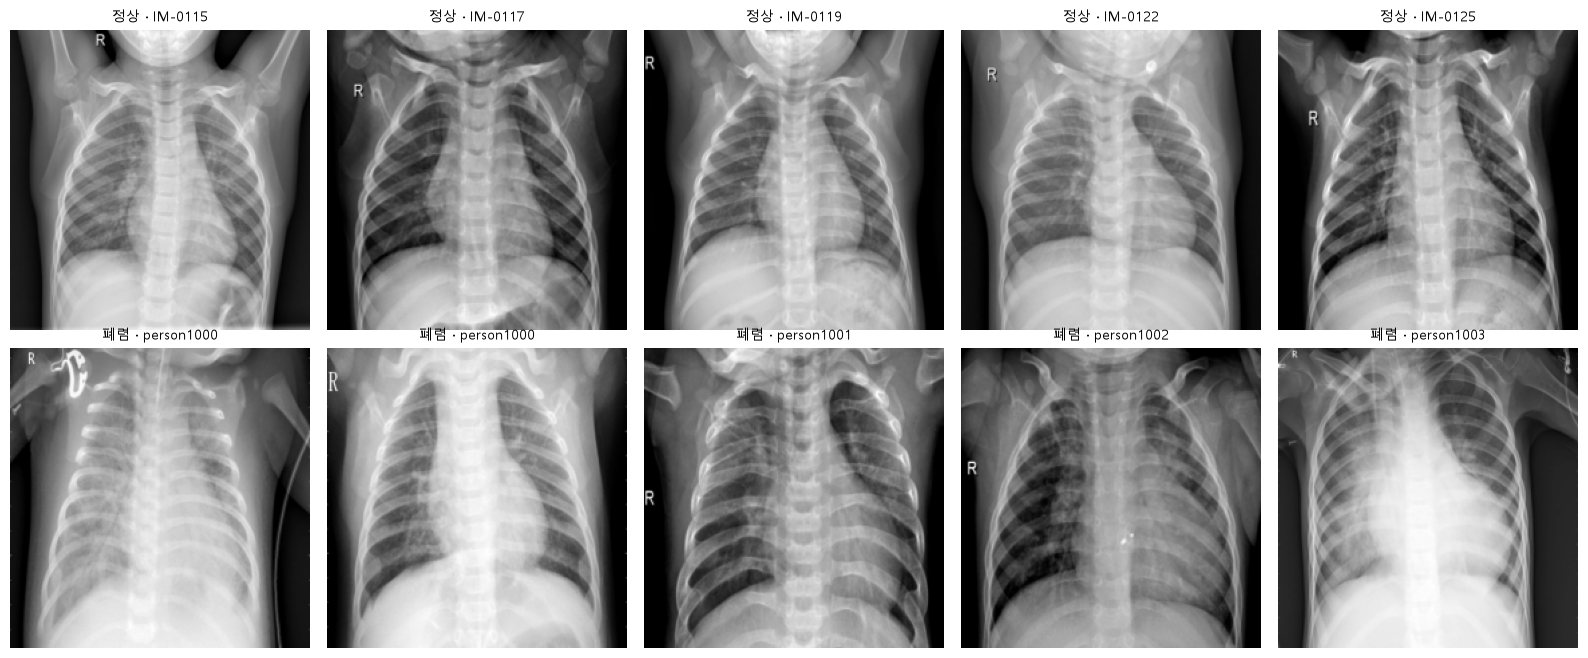

In [5]:
# 이미지 읽기 함수
def load_gray(path):  # 모든 분할을 같은 방식으로 읽기 위해
    """흑백 224×224 uint8 텐서"""
    img = Image.open(path).convert("L").resize((IMG, IMG), Image.BILINEAR)  # 채널 · 크기를 통일하기 위해
    return torch.from_numpy(np.asarray(img).copy())  # 메모리를 아끼기 위해 uint8 그대로 텐서로

# 이미지 캐시
start = time.time()  # 캐시에 걸린 시간을 재기 위해
cache = {name: torch.stack([load_gray(p) for p in d["path"]]) for name, d in [("train", train_meta), ("val", val_meta), ("test", test_meta)]}  # 매 epoch JPEG을 다시 읽지 않도록 분할별 (N, 224, 224)로 저장
print(f"이미지 캐시 완료 ({time.time() - start:.0f}초):", {k: tuple(v.shape) for k, v in cache.items()})  # 분할별 장수 · 크기를 확인하기 위해

# 정상 · 폐렴 샘플
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))  # 위 정상 · 아래 폐렴으로 비교하기 위해
for row, label in enumerate(["NORMAL", "PNEUMONIA"]):  # 클래스별로 한 줄씩 그리기 위해
    for col, i in enumerate(np.flatnonzero(train_meta["label"] == label)[:5]):  # 클래스별 앞 5장을 고르기 위해
        axes[row, col].imshow(cache["train"][i], cmap="gray")  # 흑백 X-ray를 보이기 위해
        axes[row, col].set_title(f"{'정상' if row == 0 else '폐렴'} · {train_meta['patient'][i]}", fontsize=10)  # 클래스와 환자 ID를 함께 보이기 위해
        axes[row, col].axis("off")  # 사진만 보이도록 눈금 제거
plt.tight_layout()  # 제목이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
캐시 크기 (4462 · 744 · 618, 224, 224) : 2-1 분할 결과와 장수 일치, 이후 epoch마다 디코딩 없이 재사용
소요 시간 32초                         : 이미지 5,824장을 한 번만 읽은 시간 (실행 환경마다 다름)
폐렴 샘플                              : 폐 영역에 뿌옇게 흰 음영(침윤)이 퍼짐
정상 샘플                              : 폐가 어둡고 혈관 · 갈비뼈 경계가 선명
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| load_gray() | 사용자 정의 함수 | 경로 → 흑백 224×224 텐서 | `load_gray(p)` |
| open() · convert() · resize() | PIL.Image | 열기 · 흑백 · 크기 변경 | `Image.open(path).convert("L").resize((IMG, IMG), ...)` |
| asarray() · flatnonzero() | numpy | 배열 변환 · True 위치 | `np.flatnonzero(train_meta["label"] == label)` |
| from_numpy() · stack() | torch | 배열 → 텐서 · 여러 장 쌓기 | `torch.stack([load_gray(p) for p in d["path"]])` |
| subplots() · imshow() · axis() | matplotlib | 2×5 칸 · 이미지 · 눈금 제거 | `axes[row, col].imshow(..., cmap="gray")` |
| enumerate() · tuple() · time() | Python 내장 함수 · time | 번호 반복 · 크기 튜플 · 소요 시간 | `time.time() - start` |

### 2-3. Dataset · DataLoader · 클래스 가중치

**한글 요약**

- **3채널 복제 + ImageNet 정규화**: 사전학습 모델의 첫 층이 RGB 입력과 ImageNet 통계에 맞춰져 있기 때문
- **증강(학습 데이터만)**: ±5° 회전, 3% 이동, 밝기 · 대비 미세 조정. **좌우 반전 제외** → 심장이 왼쪽에 있는 해부학적 구조 보존
- 폐렴이 약 3배 많은 불균형 → 손실 함수에 쓸 **클래스 가중치** 계산

<img src="images/m6_input.png" alt="흑백 X-ray를 ResNet18 입력으로 바꾸는 순서" width="816">

**실행 흐름**

1. **입력**: 2-2의 `cache` · 분할별 라벨
2. **처리**: ImageNet 평균 · 표준편차, 증강 정의 → Dataset(흑백 → 3채널 → 증강 → 정규화) → DataLoader → 클래스 가중치
3. **저장**: `XrayDataset` · `loaders` · `class_weight`
4. **출력**: 클래스 가중치

In [6]:
# 정규화 · 증강 설정
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)  # 사전학습 모델이 배운 ImageNet 채널별 평균에 맞추기 위해
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)  # 사전학습 모델이 배운 ImageNet 채널별 표준편차에 맞추기 위해
augment = v2.Compose([v2.RandomAffine(degrees=5, translate=(0.03, 0.03)), v2.ColorJitter(brightness=0.1, contrast=0.1)])  # 촬영 자세 · 조건 차이만 흉내 내기 위해 (해부학 구조를 지키려 좌우 반전 제외)

# Dataset 클래스
class XrayDataset(Dataset):  # 캐시 텐서를 모델 입력 형태로 바꿔 공급하기 위해
    """캐시 텐서 → 정규화된 3채널 이미지 + 라벨"""
    def __init__(self, images, labels, train=False):  # 학습 데이터에서만 증강하기 위해 train 여부를 받음
        self.images, self.labels, self.train = images, torch.tensor(labels.to_numpy()), train  # 이미지 · 라벨 · 증강 여부를 기억하기 위해
    def __len__(self):  # DataLoader가 데이터 수를 알도록
        return len(self.images)  # 전체 이미지 수를 돌려주기 위해
    def __getitem__(self, i):  # 이미지 1장을 꺼내기 위해
        x = self.images[i].unsqueeze(0).float().div(255).expand(3, -1, -1)  # 0~1 실수로 바꾸고 RGB 입력에 맞게 흑백을 3채널로 복제
        if self.train:  # 학습 데이터에만 증강을 적용하기 위해
            x = augment(x)  # 매번 조금씩 다른 이미지를 보게 하기 위해
        return (x - MEAN) / STD, self.labels[i]  # ImageNet 통계로 정규화해 돌려주기 위해

# DataLoader
loaders = {
    "train": DataLoader(XrayDataset(cache["train"], train_meta["y"], train=True), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED)),  # 64장씩 섞되 순서를 재현하기 위해
    "val": DataLoader(XrayDataset(cache["val"], val_meta["y"]), batch_size=128),  # 평가는 증강 없이 순서대로 하기 위해
    "test": DataLoader(XrayDataset(cache["test"], test_meta["y"]), batch_size=128),  # 최종 평가도 같은 방식으로 하기 위해
}

# 클래스 가중치
counts = np.bincount(train_meta["y"])  # [정상 수, 폐렴 수]를 세기 위해
class_weight = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32, device=device)  # 적은 클래스(정상)의 손실을 크게 반영하기 위해
print("클래스 가중치 [정상, 폐렴]:", class_weight.cpu().numpy().round(3))  # 정상 쪽 가중치가 더 큰지 확인하기 위해

클래스 가중치 [정상, 폐렴]: [1.932 0.675]


**결과 해설**

```
클래스 가중치 [1.932, 0.675] : 정상 1,155장 · 폐렴 3,307장 → 적은 정상 쪽 손실을 약 2.9배 크게 반영
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| XrayDataset | 사용자 정의 클래스 | 캐시 → 정규화된 3채널 + 라벨 | `XrayDataset(cache["train"], train_meta["y"], train=True)` |
| Dataset · DataLoader() | torch.utils.data | 데이터셋 틀 · 배치 공급 | `DataLoader(..., batch_size=64, shuffle=True, ...)` |
| Compose() · RandomAffine() · ColorJitter() | torchvision.transforms.v2 | 증강 연결 · 회전 · 이동 · 밝기 · 대비 | `v2.RandomAffine(degrees=5, translate=(0.03, 0.03))` |
| view() · unsqueeze() · expand() · div() | torch.Tensor | 모양 · 차원 추가 · 3채널 복제 · 0~1 | `.expand(3, -1, -1)` |
| bincount() · round() | numpy | 클래스별 개수 · 반올림 | `np.bincount(train_meta["y"])` |
| class · __getitem__ | Python 기본 문법 | DataLoader가 쓰는 인덱싱 | `def __getitem__(self, i):` |

---
## 3. 모델 학습

### 비교할 4개 모델

| 모델 | 학습하는 부분 | 학습률 |
| :-- | :-- | :-- |
| **Custom CNN** | 전부 (처음부터 학습) | 1e-3 |
| **ResNet18 · Feature Extraction** | 분류층(fc)만, 사전학습 특징 추출기는 고정 | fc 1e-3 |
| **ResNet18 · Partial Fine-Tuning** | 마지막 블록(layer4) + fc | layer4 1e-4 · fc 1e-3 |
| **ResNet18 · Full Fine-Tuning** | 전부 | 앞쪽 층 1e-5 · layer4 1e-4 · fc 1e-3 |

- **층별 학습률**: 사전학습 가중치에 가까운 층일수록 작은 학습률 → 잘 배운 일반 특징 보존
- 고정한 층의 **BatchNorm 통계도 함께 고정**
- 기본 예시 코드의 오류 수정: 전이학습 옵티마이저에 `model.parameters()`(앞서 만든 Custom CNN의 파라미터)를 넘겨 ResNet이 학습되지 않고 정확도가 0.62 부근에 고정 → 각 모델의 학습 대상 파라미터를 직접 전달

### 3-1. 비교할 4개 모델 · Custom CNN

**한글 요약**

처음부터 학습하는 비교 기준 모델. 합성곱-정규화-활성화-풀링 블록 4개 뒤 전역 평균 풀링 · Dropout · 분류층.

**실행 흐름**

1. **입력**: (3, 224, 224) 정규화 이미지
2. **처리**: 블록 4개(채널 2배 · 크기 절반) → 전역 평균 풀링 → Dropout → 2클래스 점수
3. **저장**: `CustomCNN` 클래스
4. **출력**: 없음 (정의 셀)

In [7]:
# Custom CNN
class CustomCNN(nn.Module):  # 사전학습 없이 처음부터 학습하는 비교 기준을 만들기 위해
    """Conv-BN-ReLU-MaxPool × 4 → 전역 평균 풀링 → Dropout → Linear"""
    def __init__(self):  # 층을 만들기 위해
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        layers, cin = [], 3  # RGB 3채널 입력부터 층을 쌓기 위해
        for cout in [32, 64, 128, 256]:  # 블록마다 채널을 2배로 늘려 더 복잡한 특징을 담기 위해
            layers += [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2)]  # 특징을 뽑고 크기를 절반으로 줄이기 위해
            cin = cout  # 다음 블록의 입력 채널을 맞추기 위해
        self.features = nn.Sequential(*layers)  # 합성곱 블록 4개를 하나로 묶기 위해
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 2))  # 과적합을 줄인 뒤 2클래스 점수를 내기 위해
    def forward(self, x):  # model(x)로 호출할 때 실행되도록
        return self.head(self.features(x))  # 특징을 뽑은 뒤 분류하기 위해

**결과 해설**

```
출력 없음 : Custom CNN 정의, 파라미터 수는 다음 셀에서 다른 모델과 함께 확인
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| CustomCNN | 사용자 정의 클래스 | 합성곱 4블록 분류 모델 | `class CustomCNN(nn.Module):` |
| Conv2d · BatchNorm2d · ReLU · MaxPool2d | torch.nn | 합성곱 · 정규화 · 활성화 · 크기 절반 | `nn.Conv2d(cin, cout, 3, padding=1)` |
| AdaptiveAvgPool2d · Flatten · Dropout · Linear | torch.nn | 전역 평균 · 펼치기 · 과적합 억제 · 분류층 | `nn.Dropout(0.3)` · `nn.Linear(256, 2)` |
| class · super() · * 풀기 · += | Python 기본 문법 | 상속 · 부모 초기화 · 목록 펼치기 · 층 추가 | `nn.Sequential(*layers)` |

### 3-1. 비교할 4개 모델 · 생성 함수와 학습 범위

**한글 요약**

모델 이름에 따라 Custom CNN 또는 사전학습 ResNet18을 만들고, **층별 학습률 그룹**을 구성해 그룹 밖 파라미터는 고정. 고정한 층의 BatchNorm 통계도 고정.

<img src="images/m6_transfer.png" alt="전이학습 3방식의 학습 범위와 층별 학습률" width="837">

**실행 흐름**

1. **입력**: 모델 이름 4개
2. **처리**: ResNet18 분류층 교체 → 층 이름으로 학습률 그룹 구성 → 그룹 밖 고정 → 고정 BN eval
3. **저장**: `build` · `freeze_frozen_bn` 함수
4. **출력**: 모델별 학습 파라미터 수

In [8]:
# 모델 생성 함수
def build(name):  # 네 모델을 같은 방식으로 만들기 위해
    """모델 + 파라미터 그룹별 학습률, 그룹 밖 파라미터는 고정"""
    if name == "Custom CNN":  # 처음부터 학습하는 모델이면
        model = CustomCNN()  # 무작위 초기화로 만들기 위해
        return model, [{"params": list(model.parameters()), "lr": 1e-3}]  # 전체를 같은 학습률로 학습하기 위해
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # ImageNet 사전학습 가중치에서 출발하기 위해
    model.fc = nn.Linear(model.fc.in_features, 2)  # 1000클래스 분류층을 2클래스로 바꾸기 위해
    plan = {"fc": 1e-3}  # 새로 만든 분류층은 큰 학습률로 빠르게 배우기 위해
    if name in ("ResNet18 · Partial", "ResNet18 · Full"):  # 백본 일부도 학습하는 경우
        plan["layer4"] = 1e-4  # 마지막 블록을 조심스럽게 미세 조정하기 위해
    if name == "ResNet18 · Full":  # 전체를 학습하는 경우
        plan["앞쪽 층"] = 1e-5  # 잘 배운 일반 특징을 지키기 위해 아주 작은 학습률
    groups = []  # 옵티마이저에 넘길 파라미터 그룹을 모으기 위해
    for part, lr in plan.items():  # 계획한 부분마다 그룹을 만들기 위해
        params = [p for n, p in model.named_parameters()
                  if (n.startswith(part) if part != "앞쪽 층" else not n.startswith(("layer4", "fc")))]  # 파라미터 이름으로 어느 층인지 구분하기 위해
        groups.append({"params": params, "lr": lr})  # 층별 학습률을 지정하기 위해
    trainable = {id(p) for g in groups for p in g["params"]}  # 학습할 파라미터를 빠르게 찾기 위해
    for p in model.parameters():  # 모든 파라미터의 학습 여부를 정하기 위해
        p.requires_grad = id(p) in trainable  # 그룹 밖 파라미터는 고정하기 위해
    return model, groups  # 모델과 학습률 그룹을 함께 돌려주기 위해

# 고정 BatchNorm 함수
def freeze_frozen_bn(model):  # 고정한 층이 학습 중에도 통계를 바꾸지 않도록
    """학습하지 않는 BatchNorm은 eval 모드로 통계(평균 · 분산)까지 고정"""
    for m in model.modules():  # 모든 층을 확인하기 위해
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):  # 고정된 BatchNorm만 고르기 위해
            m.eval()  # 이동 평균이 갱신되지 않도록

# 모델별 학습 파라미터 수
for name in ["Custom CNN", "ResNet18 · Feature Extraction", "ResNet18 · Partial", "ResNet18 · Full"]:  # 네 모델의 학습 범위를 비교하기 위해
    model, groups = build(name)  # 모델을 만들기 위해
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)  # 실제로 학습되는 값 개수를 세기 위해
    print(f"{name:<30} 학습 파라미터 {trainable:>10,} / 전체 {sum(p.numel() for p in model.parameters()):,}")  # 학습 범위를 비교하기 위해

Custom CNN                     학습 파라미터    389,890 / 전체 389,890
ResNet18 · Feature Extraction  학습 파라미터      1,026 / 전체 11,177,538


ResNet18 · Partial             학습 파라미터  8,394,754 / 전체 11,177,538
ResNet18 · Full                학습 파라미터 11,177,538 / 전체 11,177,538


**결과 해설**

```
Custom CNN 389,890개       : 전부 학습, ResNet18의 약 3.5% 크기
Feature Extraction 1,026개 : fc(512×2 + 2)만 학습, 나머지 고정
Partial 8,394,754개        : layer4 + fc, 전체의 약 75%
Full 11,177,538개          : 전체 학습, 층별 학습률만 다름
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| build() · freeze_frozen_bn() | 사용자 정의 함수 | 모델 + 층별 학습률 그룹 · 고정 BN 통계 고정 | `build(name)` · `freeze_frozen_bn(model)` |
| resnet18() · ResNet18_Weights.DEFAULT | torchvision.models | ResNet18 · 사전학습 가중치 | `models.resnet18(weights=models.ResNet18_Weights.DEFAULT)` |
| named_parameters() · modules() · eval() | torch.nn.Module | 이름 붙은 파라미터 · 층 순회 · 평가 모드 | `model.named_parameters()` |
| requires_grad · numel() | torch.Tensor | 학습 여부 · 원소 개수 | `p.requires_grad = id(p) in trainable` |
| startswith() · id() · isinstance() · any() | Python 내장 | 층 이름 구분 · 객체 번호 · 자료형 · 하나라도 | `n.startswith(("layer4", "fc"))` |
| 조건 컴프리헨션 · f-string 정렬 | Python 기본 문법 | 조건 파라미터 목록 · 정렬 출력 | `{name:<30}` · `{trainable:>10,}` |

### 3-2. 예측 · 평가 함수

**한글 요약**

- **예측 함수**: 모델 출력의 softmax에서 폐렴 확률만 추출
- **평가 함수**: 임계값 기준 정확도 · 재현율 · 특이도 · 정밀도 · F1 · ROC-AUC · 놓친 폐렴(FN) · 오진(FP)

**실행 흐름**

1. **입력**: 모델 · DataLoader, 정답 · 폐렴 확률
2. **처리**: 배치별 softmax → 폐렴 확률 이어 붙이기 / 확률 → 0·1 예측 → 혼동행렬 → 지표 8개
3. **저장**: `predict` · `metrics` 함수
4. **출력**: 없음 (정의 셀)

In [9]:
# 예측 함수
@torch.no_grad()  # 예측에는 기울기가 필요 없어 메모리 · 시간을 아끼기 위해
def predict(model, loader):  # 검증 · test에서 같은 방식으로 확률을 얻기 위해
    """loader 전체의 폐렴 확률 배열"""
    model.eval()  # Dropout을 끄고 BN 통계를 고정하기 위해
    probs = [torch.softmax(model(x.to(device)), 1)[:, 1].float().cpu() for x, _ in loader]  # 배치별로 폐렴 확률만 꺼내기 위해
    return torch.cat(probs).numpy()  # 배치 결과를 하나의 배열로 이어 붙이기 위해

# 평가 지표 함수
def metrics(y, prob, thr=0.5):  # 모든 평가에서 같은 지표를 쓰기 위해
    """임계값 thr 기준 지표 8개"""
    pred = (prob >= thr).astype(int)  # 확률을 0 · 1 예측으로 바꾸기 위해
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()  # 혼동행렬 4칸에서 지표를 계산하기 위해
    return {"정확도": (tp + tn) / len(y), "재현율(폐렴)": tp / (tp + fn), "특이도(정상)": tn / (tn + fp),
            "정밀도": precision_score(y, pred, zero_division=0), "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, prob),
            "놓친 폐렴(FN)": int(fn), "오진(FP)": int(fp)}  # 비율 지표와 실제 건수를 함께 보기 위해

**결과 해설**

```
출력 없음 : 예측 · 평가 함수 정의, 다음 셀 끝에서 작은 예시로 검증
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| predict() · metrics() | 사용자 정의 함수 | 폐렴 확률 · 지표 8개 | `metrics(y, prob, thr=0.5)` |
| no_grad() · softmax() · cat() | torch | 기울기 끄기 · 확률 · 이어 붙이기 | `torch.softmax(model(x.to(device)), 1)[:, 1]` |
| confusion_matrix() · precision_score() · f1_score() · roc_auc_score() | sklearn.metrics | 혼동행렬 · 정밀도 · F1 · AUC | `confusion_matrix(y, pred, labels=[0, 1]).ravel()` |
| @ 데코레이터 · 튜플 풀기 | Python 기본 문법 | 함수에 no_grad 적용 · 4칸 분리 | `tn, fp, fn, tp = ...` |

### 3-2. 학습 함수와 평가 함수 검증

**한글 요약**

- **학습 함수**: AdamW + 코사인 학습률 감소 + 혼합 정밀도(AMP), 매 epoch 검증 ROC-AUC가 가장 높은 시점의 가중치 반환
- 정답을 아는 작은 예시로 평가 함수 검증

**실행 흐름**

1. **입력**: 모델 이름 · epoch 수
2. **처리**: 시드 고정 → 모델 · 학습률 그룹 → 배치 학습(AMP) → epoch마다 검증 ROC-AUC → 최고 가중치 복원
3. **저장**: `train` 함수
4. **출력**: 평가 함수 검증 결과

In [10]:
# 학습 함수
def train(name, epochs):  # 네 모델을 같은 조건으로 학습하기 위해
    """검증 ROC-AUC 최고 epoch의 모델 · 학습 기록 · 소요 시간 반환"""
    seed_all()  # 모델마다 같은 출발점에서 시작하기 위해
    model, groups = build(name)  # 모델과 층별 학습률 그룹을 만들기 위해
    model = model.to(device)  # GPU에서 학습하기 위해
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)  # 층별 학습률 그룹을 그대로 쓰기 위해
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)  # 학습 후반에 학습률을 줄여 안정적으로 수렴하기 위해
    criterion = nn.CrossEntropyLoss(weight=class_weight)  # 클래스 불균형을 보정하기 위해
    scaler = torch.amp.GradScaler(enabled=device == "cuda")  # 혼합 정밀도에서 작은 기울기가 0이 되지 않도록
    best_auc, best_state, history, start = -1, None, [], time.time()  # 최고 기록 · 가중치 · 곡선 · 시작 시각을 준비하기 위해
    for epoch in range(epochs):  # 정해진 epoch만큼 학습하기 위해
        model.train()  # 학습 모드로 바꾸기 위해
        freeze_frozen_bn(model)  # train()이 되살린 고정 층 BN을 다시 eval로 돌리기 위해
        total = 0.0  # epoch 평균 손실을 구하기 위해
        for x, yb in loaders["train"]:  # 배치 단위로 학습하기 위해
            x, yb = x.to(device), yb.to(device)  # GPU에서 계산하기 위해
            optimizer.zero_grad()  # 이전 기울기가 섞이지 않도록
            with torch.autocast(device_type=device, enabled=device == "cuda"):  # 반정밀도 연산으로 속도를 높이기 위해
                loss = criterion(model(x), yb)  # 가중 교차 엔트로피를 구하기 위해
            scaler.scale(loss).backward()  # 스케일한 손실로 기울기를 구하기 위해
            scaler.step(optimizer)  # 기울기를 되돌린 뒤 가중치를 갱신하기 위해
            scaler.update()  # 다음 배치의 스케일을 조정하기 위해
            total += loss.item() * len(x)  # 배치 크기만큼 가중해 합치기 위해
        scheduler.step()  # epoch마다 학습률을 줄이기 위해
        m = metrics(val_meta["y"].to_numpy(), predict(model, loaders["val"]))  # 최고 epoch를 고르기 위해 검증 지표 계산
        history.append({"epoch": epoch + 1, "train_loss": total / len(loaders["train"].dataset), "val_auc": m["ROC-AUC"], "val_f1": m["F1"]})  # 학습 곡선을 그리기 위해 기록
        if m["ROC-AUC"] > best_auc:  # 검증 최고 기록이면 저장하기 위해
            best_auc, best_state = m["ROC-AUC"], copy.deepcopy(model.state_dict())  # 이후 학습이 덮어써도 보존되도록 복사
    model.load_state_dict(best_state)  # 마지막이 아닌 최고 epoch 가중치로 평가하기 위해
    return model, pd.DataFrame(history), time.time() - start  # 모델 · 기록 · 소요 시간을 함께 돌려주기 위해

# 평가 함수 검증
check = metrics(np.array([0, 0, 1, 1]), np.array([0.2, 0.7, 0.4, 0.9]))  # 답을 아는 예시로 평가 함수를 확인하기 위해 (정상 1장 오진, 폐렴 1장 놓침)
assert (check["놓친 폐렴(FN)"], check["오진(FP)"], check["재현율(폐렴)"], check["특이도(정상)"]) == (1, 1, 0.5, 0.5)  # 손 계산과 같은지 확인하기 위해
print("✅ 통과: 평가 함수", {k: round(float(v), 2) for k, v in check.items()})  # 지표 8개를 확인하기 위해

✅ 통과: 평가 함수 {'정확도': 0.5, '재현율(폐렴)': 0.5, '특이도(정상)': 0.5, '정밀도': 0.5, 'F1': 0.5, 'ROC-AUC': 0.75, '놓친 폐렴(FN)': 1.0, '오진(FP)': 1.0}


**결과 해설**

```
✅ 통과 : 정답 [0, 0, 1, 1] · 확률 [0.2, 0.7, 0.4, 0.9] → FN 1 · FP 1 · 재현율 0.5 · 특이도 0.5, 손 계산과 일치
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train() | 사용자 정의 함수 | 학습 + 최고 epoch 복원 | `train(name, epochs)` |
| AdamW() · CosineAnnealingLR() | torch.optim | 가중치 감쇠 Adam · 코사인 학습률 감소 | `CosineAnnealingLR(optimizer, T_max=epochs)` |
| CrossEntropyLoss(weight) | torch.nn | 클래스 가중 교차 엔트로피 | `nn.CrossEntropyLoss(weight=class_weight)` |
| autocast() · amp.GradScaler() | torch | 혼합 정밀도 · 손실 스케일링 | `torch.amp.GradScaler(enabled=device == "cuda")` |
| state_dict() · load_state_dict() · deepcopy() | torch · copy | 가중치 저장 · 복원 · 복사 | `copy.deepcopy(model.state_dict())` |
| with · assert · 튜플 비교 | Python 기본 문법 | autocast 구간 · 지표 4개 검사 | `assert (...) == (1, 1, 0.5, 0.5)` |

### 3-3. 4개 모델 학습과 검증 성능

**한글 요약**

4개 모델을 같은 데이터 · 같은 시드로 학습. 처음부터 학습하는 Custom CNN만 15 epoch, ResNet18 세 방식은 10 epoch. 각 모델의 **검증 ROC-AUC 최고 시점** 기준으로 검증 지표 표 작성.

**실행 흐름**

1. **입력**: 모델 이름 · epoch 수
2. **처리**: 모델별 학습(최고 epoch 복원) → 검증 지표 · 학습 시간 기록
3. **저장**: `trained` · `histories` · `val_table`
4. **출력**: 모델별 진행 문장, 검증 성능 표

In [11]:
# 4개 모델 학습
EPOCHS = {"Custom CNN": 15, "ResNet18 · Feature Extraction": 10, "ResNet18 · Partial": 10, "ResNet18 · Full": 10}  # 처음부터 학습하는 CNN은 수렴이 느려 더 길게
trained, histories, val_rows = {}, {}, []  # 4장 평가 · 3-4 곡선에 다시 쓰기 위해 결과를 모음
for name, epochs in EPOCHS.items():  # 네 모델을 같은 반복문으로 학습하기 위해
    model, hist, sec = train(name, epochs)  # 학습하고 최고 epoch 가중치로 복원하기 위해
    trained[name], histories[name] = model, hist  # 이후 평가 · 그래프에서 쓰기 위해
    val_rows.append({"모델": name, "epoch": epochs, "학습 시간(초)": round(sec), **metrics(val_meta["y"].to_numpy(), predict(model, loaders["val"]))})  # 최고 epoch 기준 검증 지표를 한 행에 담기 위해
    print(f"{name:<30} 검증 ROC-AUC {val_rows[-1]['ROC-AUC']:.4f} · F1 {val_rows[-1]['F1']:.4f} · {sec:.0f}초")  # 진행 상황을 확인하기 위해

# 검증 성능 표
val_table = pd.DataFrame(val_rows).set_index("모델")  # 모델 × 지표 표로 보기 위해
val_table.style.format({c: "{:.4f}" for c in ["정확도", "재현율(폐렴)", "특이도(정상)", "정밀도", "F1", "ROC-AUC"]})  # 작은 차이도 읽히도록 소수 넷째 자리

Custom CNN                     검증 ROC-AUC 0.9969 · F1 0.9819 · 624초


ResNet18 · Feature Extraction  검증 ROC-AUC 0.9921 · F1 0.9487 · 155초


ResNet18 · Partial             검증 ROC-AUC 0.9990 · F1 0.9927 · 153초


ResNet18 · Full                검증 ROC-AUC 0.9993 · F1 0.9918 · 258초


,epoch,학습 시간(초),정확도,재현율(폐렴),특이도(정상),정밀도,F1,ROC-AUC,놓친 폐렴(FN),오진(FP)
모델,,,,,,,,,,
Custom CNN,15,624,0.9731,0.9873,0.9326,0.9767,0.9819,0.9969,7,13
ResNet18 · Feature Extraction,10,155,0.9274,0.9056,0.9896,0.9960,0.9487,0.9921,52,2
ResNet18 · Partial,10,153,0.9892,0.9927,0.9793,0.9927,0.9927,0.9990,4,4
ResNet18 · Full,10,258,0.9879,0.9855,0.9948,0.9982,0.9918,0.9993,8,1


**결과 해설**

```
Full 0.9993 · Partial 0.9990    : 백본까지 미세 조정한 두 모델이 최고, 놓친 폐렴 4~8장 · 오진 1~4장
Feature Extraction 재현율 0.906 : 특이도 0.990이지만 폐렴 52장 놓침
Custom CNN 0.9969               : 처음부터 학습해도 검증에서는 높음
학습 시간                       : Custom CNN 624초 · Feature Extraction 155초 · Partial 153초 · Full 258초 (실행 환경마다 다름)
```

- ImageNet 일반 사진 특징만으로는 X-ray의 미세한 음영 차이 부족 → **백본까지 학습하는 것이 핵심**
- 학습 데이터와 같은 출처의 검증에서는 모든 모델이 거의 완벽 → 진짜 차이는 4장 test에서 확인

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train() · metrics() · predict() | 사용자 정의 함수 | 학습 · 검증 지표 · 확률 | `metrics(..., predict(model, loaders["val"]))` |
| DataFrame() · set_index() · style.format() | pandas | 지표 표 · 행 이름 · 서식 | `val_table.style.format({...})` |
| round() · print() | Python 내장 함수 | 학습 시간 정수 · 진행 상황 | `round(sec)` |
| ** 풀기 · { ... for ... } | Python 기본 문법 | 지표를 한 행에 · 열별 서식 | `{"모델": name, ..., **metrics(...)}` |

### 3-4. 학습 곡선

**한글 요약**

모델별 epoch에 따른 **학습 손실**과 **검증 ROC-AUC** 변화 비교. 수렴 속도와 과적합 여부 확인.

**실행 흐름**

1. **입력**: 3-3의 `histories`
2. **처리**: 왼쪽: 학습 손실 / 오른쪽: 검증 ROC-AUC
3. **저장**: 없음
4. **출력**: 학습 곡선 2칸

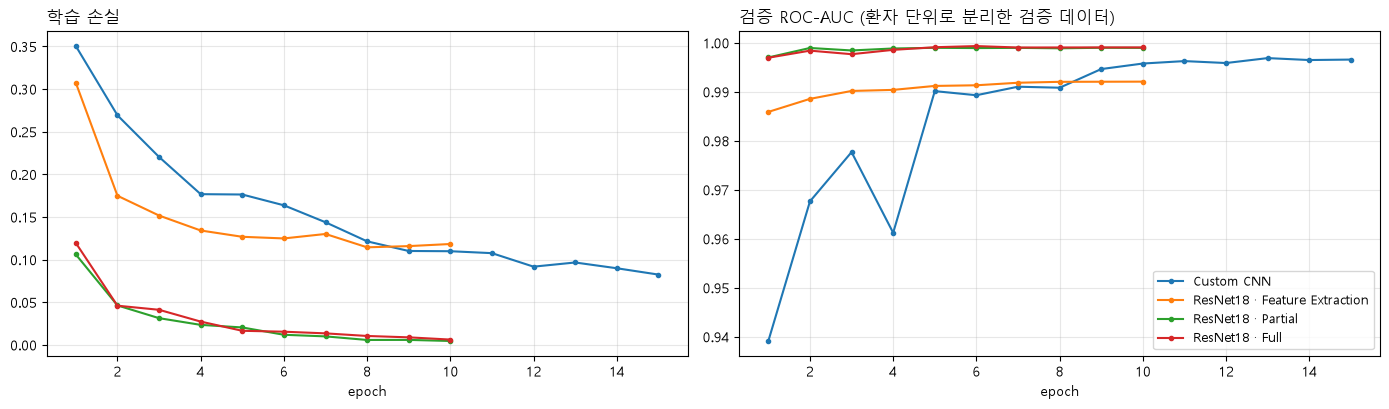

In [12]:
# 학습 곡선
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))  # 손실과 AUC를 나란히 비교하기 위해
for name, hist in histories.items():  # 모델마다 선 하나씩 그리기 위해
    axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", markersize=3, label=name)  # 학습이 수렴하는지 보기 위해
    axes[1].plot(hist["epoch"], hist["val_auc"], marker="o", markersize=3, label=name)  # 검증 성능 변화를 보기 위해

# 축 · 제목
axes[0].set_title("학습 손실", loc="left")  # 왼쪽 그래프 내용을 알리기 위해
axes[1].set_title("검증 ROC-AUC (환자 단위로 분리한 검증 데이터)", loc="left")  # 어떤 검증 데이터인지 알리기 위해
for ax in axes:  # 두 칸에 같은 설정을 하기 위해
    ax.set_xlabel("epoch")  # 가로축 의미를 알리기 위해
    ax.grid(alpha=0.3)  # 값을 읽기 쉽도록 옅은 격자
axes[1].legend(loc="lower right", fontsize=9)  # 모델별 선을 구분하기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
Partial · Full     : 1 epoch부터 검증 ROC-AUC 0.997, 학습 손실 0.01 이하까지 빠르게 감소
Feature Extraction : 손실 0.12 · 검증 ROC-AUC 0.99 초반에서 정체 → 분류층만으로는 한계
Custom CNN         : 초반 검증 ROC-AUC 0.94~0.98로 출렁, 5 epoch 이후 0.99 이상 안정 → 15 epoch에 0.997
```

- 사전학습 가중치를 함께 미세 조정한 모델이 **가장 빠르고 안정적으로 수렴**
- 검증 ROC-AUC가 학습 후반에 떨어지지 않음 → 검증 데이터 기준 뚜렷한 과적합 없음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| subplots() · plot() · set_title() · grid() · legend() | matplotlib | 그래프 칸 · 선 · 제목 · 격자 · 범례 | `axes[0].plot(hist["epoch"], hist["train_loss"], ...)` |
| items() | Python dict | 모델 이름 · 기록 쌍 | `histories.items()` |
| for | Python 기본 문법 | 모델 · 칸 반복 | `for ax in axes:` |

---
## 4. 최종 평가 (test 618장)

### 4-1. test 성능 비교

**한글 요약**

학습 · 모델 선택에 쓰지 않은 test에서 4개 모델을 **한 번만** 평가. 임계값 0.5 기준 지표 8개를 한 표로 정리하고, ROC-AUC · F1 · 특이도 최고값 강조.

**실행 흐름**

1. **입력**: 학습된 4개 모델 · test DataLoader
2. **처리**: 모델별 폐렴 확률 → 지표 8개
3. **저장**: `y_test` · `test_prob` · `test_table`
4. **출력**: 모델 × 지표 표 (최고값 강조)

In [13]:
# test 지표
y_test = test_meta["y"].to_numpy()  # test 정답을 배열로 쓰기 위해
test_prob = {name: predict(model, loaders["test"]) for name, model in trained.items()}  # 4-2 · 4-3에서 재사용하도록 모델별 확률을 한 번만 계산
test_table = pd.DataFrame({name: metrics(y_test, p) for name, p in test_prob.items()}).T  # 모델을 행으로 비교하기 위해

# 최고값 강조 표
fmt = {**{c: "{:.4f}" for c in ["정확도", "재현율(폐렴)", "특이도(정상)", "정밀도", "F1", "ROC-AUC"]}, "놓친 폐렴(FN)": "{:.0f}", "오진(FP)": "{:.0f}"}  # 비율은 소수 넷째 자리, 개수는 정수로 보이기 위해
test_table.style.format(fmt).highlight_max(subset=["ROC-AUC", "F1", "특이도(정상)"], color="#d4edda")  # 지표별 최고 모델을 한눈에 보기 위해

,정확도,재현율(폐렴),특이도(정상),정밀도,F1,ROC-AUC,놓친 폐렴(FN),오진(FP)
Custom CNN,0.7961,0.9974,0.4589,0.7554,0.8597,0.9412,1,125
ResNet18 · Feature Extraction,0.9061,0.9406,0.8485,0.9123,0.9262,0.9575,23,35
ResNet18 · Partial,0.8528,0.9974,0.6104,0.8109,0.8946,0.9578,1,90
ResNet18 · Full,0.8738,0.9948,0.6710,0.8351,0.9080,0.9593,2,76


**결과 해설**

```
ROC-AUC 0.94~0.96                          : 검증 0.99대에서 모든 모델 하락
Full 재현율 0.995 · 특이도 0.671           : 폐렴 387명 중 2명 놓침, 정상 231명 중 76명 오진
Custom CNN 특이도 0.459                    : 정상 125명 오진, 일반화가 가장 약함
Feature Extraction F1 0.926 · 특이도 0.849 : 가장 균형적, 다만 재현율 0.941로 폐렴 23명 놓침
```

- **검증 1위 ≠ test 1위**: 백본을 고정한 Feature Extraction이 test에서 가장 균형적 → 학습 분포에 덜 맞춘 모델이 새 분포에서 덜 흔들린 것으로 보임

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| predict() · metrics() | 사용자 정의 함수 | test 확률 · 지표 | `metrics(y_test, p)` |
| DataFrame() · T · style.highlight_max() | pandas | 모델 × 지표 · 행열 전환 · 최고값 강조 | `.highlight_max(subset=[...], color="#d4edda")` |
| to_numpy() | pandas.Series | 정답 → 배열 | `test_meta["y"].to_numpy()` |
| { ... for ... } · ** 풀기 | Python 기본 문법 | 모델별 딕셔너리 · 서식 합치기 | `{**{...}, "놓친 폐렴(FN)": "{:.0f}", ...}` |

### 4-2. ROC 곡선 · 검증 vs test · 혼동행렬

**한글 요약**

- 최종 모델은 test가 아닌 **검증 ROC-AUC 기준**으로 선택 (test 정보로 고르면 test 점수가 낙관적으로 부풀려짐)
- 4개 모델의 test ROC 곡선, 선택 모델의 **검증 vs test 지표**, test 혼동행렬을 한 줄에 표시

**실행 흐름**

1. **입력**: `val_table` · `test_prob` · `test_table`
2. **처리**: 검증 ROC-AUC 최고 모델 선택 → test ROC 곡선 → 검증 vs test 막대 → 혼동행렬(임계값 0.5)
3. **저장**: `best`
4. **출력**: ROC 곡선 · 검증 vs test 막대 · 혼동행렬 그래프

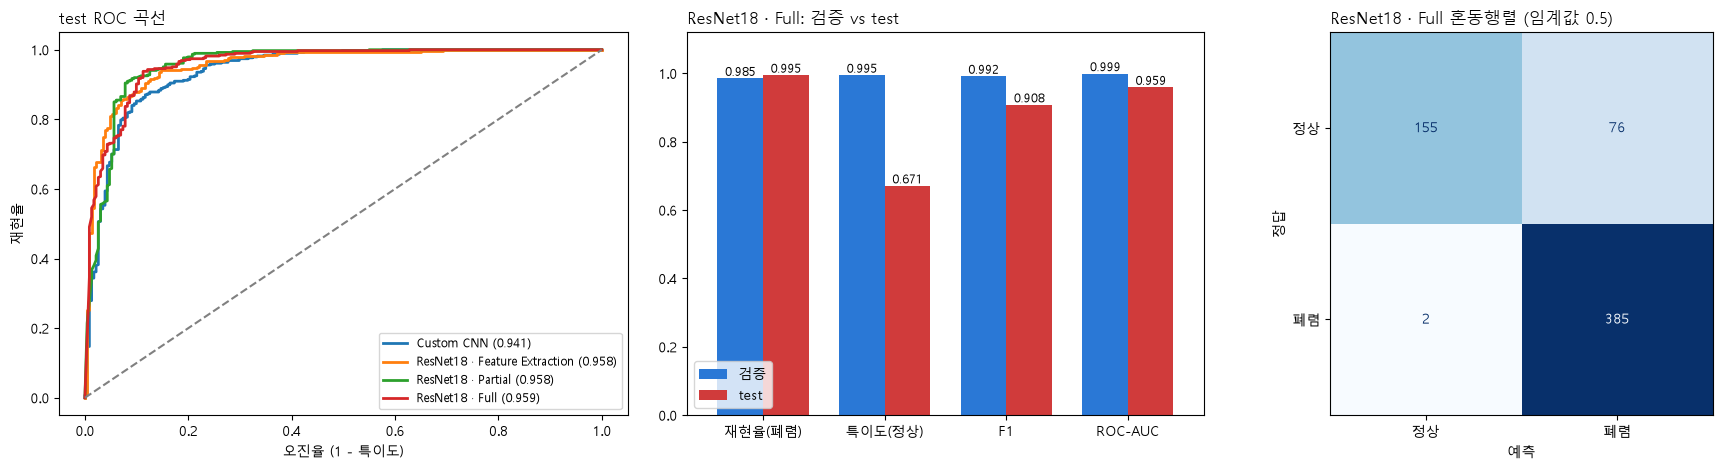

In [14]:
# 최종 모델 선택
best = val_table["ROC-AUC"].idxmax()  # test 점수가 부풀지 않도록 검증 기준으로 고르기 위해
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.1, 1, 1]})  # ROC · 검증 vs test · 혼동행렬을 한 줄에 보기 위해

# ROC 곡선
for name, p in test_prob.items():  # 모델마다 곡선 하나씩 그리기 위해
    fpr, tpr, _ = roc_curve(y_test, p)  # 임계값별 오진율 · 재현율을 구하기 위해
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} ({roc_auc_score(y_test, p):.3f})")  # 범례에 AUC를 함께 보이기 위해
axes[0].plot([0, 1], [0, 1], "--", color="gray")  # 무작위 추측과 비교하기 위해
axes[0].set_xlabel("오진율 (1 - 특이도)")  # 가로축 의미를 알리기 위해
axes[0].set_ylabel("재현율")  # 세로축 의미를 알리기 위해
axes[0].set_title("test ROC 곡선", loc="left")  # 그래프 내용을 알리기 위해
axes[0].legend(fontsize=8.5, loc="lower right")  # 모델별 곡선을 구분하기 위해

# 검증 vs test
cols = ["재현율(폐렴)", "특이도(정상)", "F1", "ROC-AUC"]  # 비교할 지표를 고르기 위해
compare = pd.DataFrame({"검증": val_table.loc[best, cols], "test": test_table.loc[best, cols]}).astype(float)  # 같은 모델의 검증 · test 점수를 나란히 놓기 위해
compare.plot.bar(ax=axes[1], color=[BLUE, RED], rot=0, width=0.75)  # 지표별로 검증 · test 막대를 비교하기 위해
for c in axes[1].containers:  # 막대 그룹마다 값을 적기 위해
    axes[1].bar_label(c, fmt="%.3f", fontsize=8.5)  # 막대 위에 점수를 보이기 위해
axes[1].set_ylim(0, 1.12)  # 값 라벨이 잘리지 않도록
axes[1].set_title(f"{best}: 검증 vs test", loc="left")  # 어떤 모델인지 알리기 위해

# 혼동행렬
ConfusionMatrixDisplay.from_predictions(y_test, (test_prob[best] >= 0.5).astype(int), display_labels=["정상", "폐렴"], cmap="Blues", ax=axes[2], colorbar=False)  # 임계값 0.5의 정답 · 오답 건수를 보기 위해
axes[2].set_title(f"{best} 혼동행렬 (임계값 0.5)", loc="left")  # 그래프 내용을 알리기 위해
axes[2].set_xlabel("예측")  # 가로축 의미를 알리기 위해
axes[2].set_ylabel("정답")  # 세로축 의미를 알리기 위해
axes[2].grid(False)  # 칸 위 격자가 숫자를 가리지 않도록
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
선택 모델 ResNet18 · Full                       : 검증 ROC-AUC 최고 (0.9993)
test ROC-AUC 0.941~0.959                        : Full 0.959 · Partial 0.958 · Feature Extraction 0.958 · Custom CNN 0.941
검증 → test 특이도 0.995 → 0.671                : 가장 크게 떨어진 지표, 재현율은 0.985 → 0.995로 유지
혼동행렬 정상 155 · 오진 76 / 놓침 2 · 폐렴 385 : 폐렴은 거의 다 잡지만 정상 1/3을 폐렴으로 판정
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| roc_curve() · roc_auc_score() · ConfusionMatrixDisplay | sklearn.metrics | 오진율 · 재현율 · AUC · 혼동행렬 그림 | `ConfusionMatrixDisplay.from_predictions(y_test, ..., ax=axes[2])` |
| idxmax() · loc[] · plot.bar() | pandas | 최고 모델 · 행열 선택 · 막대그래프 | `compare.plot.bar(ax=axes[1], ...)` |
| plot() · bar_label() · set_ylim() · grid() | matplotlib | ROC 선 · 막대 값 · 범위 · 격자 | `axes[1].bar_label(c, fmt="%.3f")` |
| astype() | numpy | True/False → 0/1 | `(test_prob[best] >= 0.5).astype(int)` |

### 4-3. 검증과 test 사이의 성능 차이

**한글 요약**

- 선택 모델의 **폐렴 확률 분포**를 검증 · test에서 비교 → 실제 정상 사진 중 확률 0.5를 넘는 비율 확인
- 검증에서 정한 임계값(**재현율 ≥ 0.98을 지키며 특이도 최대**)을 test에 적용해, 임계값 조정으로 차이가 해결되는지 확인

**실행 흐름**

1. **입력**: 선택 모델 · 검증 · test 확률
2. **처리**: 검증 · test 확률 히스토그램(실제 정상 / 폐렴) → 검증 ROC에서 재현율 ≥ 0.98 중 오진율 최소 임계값 → test에서 0.5 vs 검증 임계값
3. **저장**: `val_prob_best` · `val_thr` · `shift`
4. **출력**: 확률 분포 그래프, 임계값 비교 표

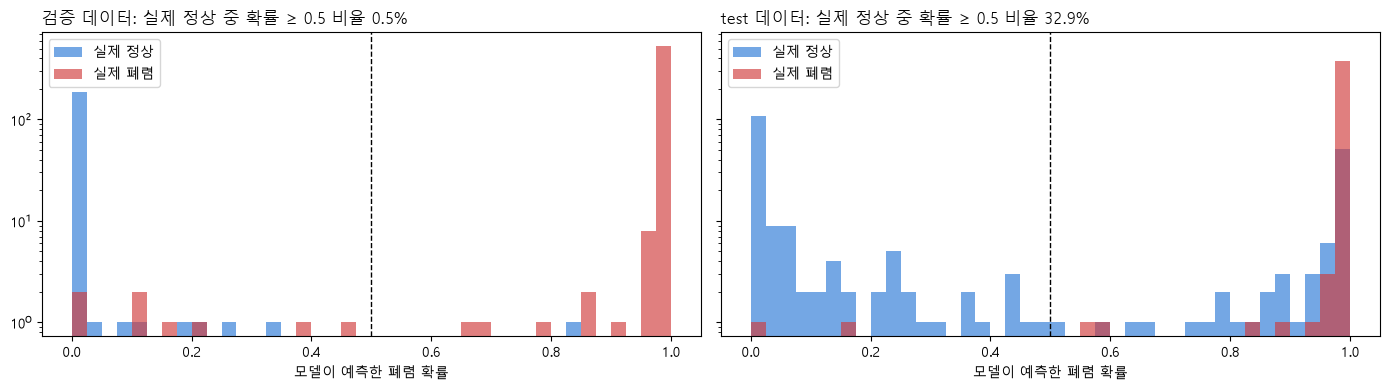

,재현율(폐렴),특이도(정상),F1,놓친 폐렴(FN),오진(FP)
임계값 0.5,0.9948,0.6710,0.9080,2,76
검증에서 정한 0.862,0.9871,0.7186,0.9161,5,65


In [15]:
# 폐렴 확률 분포
val_prob_best = predict(trained[best], loaders["val"])  # 선택 모델의 검증 확률로 분포를 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)  # 검증 · test를 같은 세로 축으로 비교하기 위해
for ax, (title, prob, y) in zip(axes, [("검증 데이터", val_prob_best, val_meta["y"].to_numpy()), ("test 데이터", test_prob[best], y_test)]):  # 두 데이터를 같은 방식으로 그리기 위해
    bins = np.linspace(0, 1, 41)  # 0.025 간격으로 나눠 분포를 보기 위해
    ax.hist(prob[y == 0], bins=bins, alpha=0.65, color=BLUE, label="실제 정상")  # 정상 사진이 폐렴처럼 보이는지 확인하기 위해
    ax.hist(prob[y == 1], bins=bins, alpha=0.65, color=RED, label="실제 폐렴")  # 폐렴 사진의 확률 분포를 보기 위해
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1)  # 기본 임계값 위치를 보이기 위해
    ax.set_yscale("log")  # 적은 개수도 보이도록 로그 축
    ax.set_xlabel("모델이 예측한 폐렴 확률")  # 가로축 의미를 알리기 위해
    ax.set_title(f"{title}: 실제 정상 중 확률 ≥ 0.5 비율 {np.mean(prob[y == 0] >= 0.5):.1%}", loc="left")  # 정상 오진 비율을 제목에 담기 위해
    ax.legend()  # 색을 구분하기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

# 검증 기준 임계값
fpr, tpr, thr = roc_curve(val_meta["y"], val_prob_best)  # 검증 데이터에서 임계값별 오진율 · 재현율을 구하기 위해
ok = tpr >= 0.98  # 폐렴을 놓치지 않는 조건(재현율 0.98 이상)을 지키기 위해
val_thr = float(thr[ok][np.argmin(fpr[ok])])  # 그 조건에서 오진율이 가장 낮은(특이도 최대) 임계값을 고르기 위해

# test 적용 비교
shift = pd.DataFrame({"임계값 0.5": metrics(y_test, test_prob[best], 0.5), f"검증에서 정한 {val_thr:.3f}": metrics(y_test, test_prob[best], val_thr)}).T  # 두 임계값의 test 지표를 나란히 비교하기 위해
shift[["재현율(폐렴)", "특이도(정상)", "F1", "놓친 폐렴(FN)", "오진(FP)"]].style.format({"재현율(폐렴)": "{:.4f}", "특이도(정상)": "{:.4f}", "F1": "{:.4f}", "놓친 폐렴(FN)": "{:.0f}", "오진(FP)": "{:.0f}"})  # 핵심 지표만 읽기 쉬운 서식으로

**결과 해설**

```
실제 정상 중 확률 ≥ 0.5 : 검증 0.5% → test 32.9%
검증 임계값 0.862       : 재현율 ≥ 0.98을 지키며 특이도가 가장 높은 값
test 적용 결과          : 특이도 0.671 → 0.719 소폭 상승, 놓친 폐렴 2명 → 5명 증가
```

- 모델이 test의 정상 사진 상당수를 폐렴처럼 봄 → 같은 기준으로 만든 검증 데이터로는 드러나지 않는 **분포 차이**
- 폐렴 비율도 학습 74% vs test 63%로 다름
- **임계값 조정만으로는 부족**: 오진은 조금 줄지만 그만큼 폐렴을 더 놓침 (놓친 폐렴 2명 → 5명)

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| predict() · metrics() | 사용자 정의 함수 | 검증 확률 · 임계값별 지표 | `metrics(y_test, ..., val_thr)` |
| roc_curve() | sklearn.metrics | 검증 임계값별 오진율 · 재현율 | `roc_curve(val_meta["y"], val_prob_best)` |
| linspace() · mean() · argmin() · 불리언 인덱싱 | numpy | 구간 · 비율 · 최솟값 위치 · 조건 선택 | `thr[ok][np.argmin(fpr[ok])]` |
| hist() · axvline() · set_yscale() | matplotlib | 히스토그램 · 임계값 선 · 로그 축 | `ax.hist(prob[y == 0], bins=bins, ...)` |
| DataFrame() · T · style.format() | pandas | 임계값 × 지표 표 · 서식 | `shift[[...]].style.format({...})` |

### 4-4. 모델은 어디를 보고 판단했나 (Grad-CAM)

**한글 요약**

- **Grad-CAM**: 마지막 합성곱 블록 출력에 대한 '폐렴' 점수의 기울기로 **판단에 크게 기여한 영역**을 열지도로 표시
- 선택 모델의 test 예측을 정답 · 오진 · 놓침 4가지 경우로 나눠 경우별 첫 사례 시각화

**실행 흐름**

1. **입력**: 선택 모델 · test 이미지 · 예측
2. **처리**: hook으로 활성값 저장 → 기울기 → 채널 가중합 → 4가지 경우별 첫 사례 → X-ray 위 열지도
3. **저장**: `grad_cam` 함수 · `picks`
4. **출력**: 4가지 경우의 Grad-CAM 그림

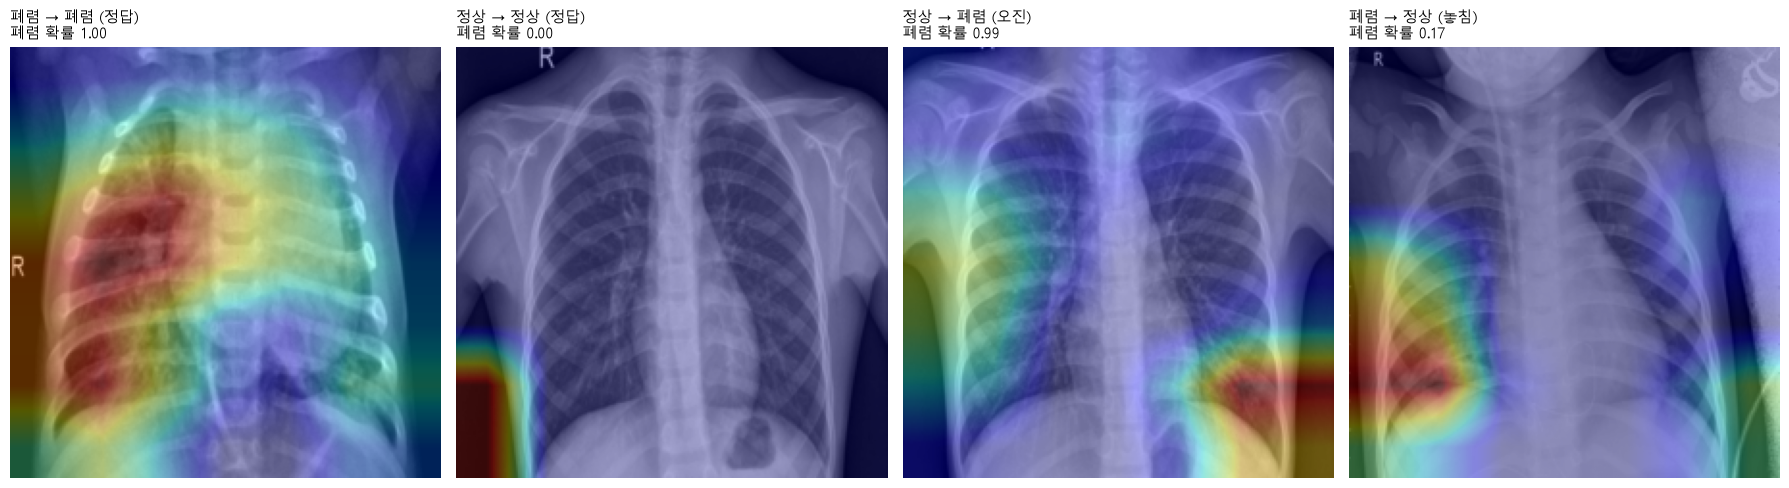

In [16]:
# Grad-CAM 함수
def grad_cam(model, x, layer):  # 모델이 어디를 보고 판단했는지 보기 위해
    """layer 출력에 대한 '폐렴' logit 기울기로 계산한 0~1 중요도 지도"""
    store = {}  # hook이 활성값을 담을 곳을 만들기 위해
    handle = layer.register_forward_hook(lambda m, i, o: store.update(act=o))  # 순전파 중 해당 층 출력을 저장하기 위해
    model.eval()  # 평가 모드로 계산하기 위해
    x = x.to(device).requires_grad_(True)  # 고정한 층도 기울기가 흐르도록
    logit = model(x)[:, 1].sum()  # 폐렴 점수를 기준으로 삼기 위해
    grad = torch.autograd.grad(logit, store["act"])[0]  # 활성값에 대한 기울기만 구하기 위해
    handle.remove()  # 다음 계산에 hook이 남지 않도록
    cam = F.relu((grad.mean((2, 3), keepdim=True) * store["act"]).sum(1, keepdim=True))  # 채널 중요도로 가중합하고 폐렴 쪽(양수)만 남기기 위해
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear")[:, 0]  # 7×7 지도를 원본 크기로 키우기 위해
    return (cam / cam.flatten(1).amax(1).clamp_min(1e-8).view(-1, 1, 1)).detach().cpu().numpy()  # 0으로 나누지 않도록 하한을 두고 최댓값 1로 정규화

# 4가지 경우 선택
model = trained[best]  # 선택 모델을 분석하기 위해
layer = model.layer4 if hasattr(model, "layer4") else model.features  # ResNet · Custom CNN 모두 마지막 합성곱 블록을 쓰기 위해
pred = (test_prob[best] >= 0.5).astype(int)  # 임계값 0.5 예측으로 경우를 나누기 위해
picks = [("폐렴 → 폐렴 (정답)", (y_test == 1) & (pred == 1)), ("정상 → 정상 (정답)", (y_test == 0) & (pred == 0)),
         ("정상 → 폐렴 (오진)", (y_test == 0) & (pred == 1)), ("폐렴 → 정상 (놓침)", (y_test == 1) & (pred == 0))]  # 실제 → 예측 4가지를 모두 보기 위해

# 열지도 시각화
fig, axes = plt.subplots(1, 4, figsize=(18, 5))  # 경우별로 한 칸씩 보기 위해
for ax, (title, mask) in zip(axes, picks):  # 경우마다 그리기 위해
    if not mask.any():  # 해당 경우가 없을 때도 멈추지 않도록
        ax.set_title(f"{title}\n해당 사례 없음", loc="left")  # 빈 칸임을 알리기 위해
        ax.axis("off")  # 빈 칸의 눈금을 지우기 위해
        continue  # 다음 경우로 넘어가기 위해
    i = np.flatnonzero(mask)[0]  # 경우별 첫 사례를 고르기 위해
    x = XrayDataset(cache["test"], test_meta["y"])[i][0].unsqueeze(0)  # 모델 입력과 같은 정규화를 한 1장을 만들기 위해
    cam = grad_cam(model, x, layer)[0]  # 중요도 지도를 구하기 위해
    ax.imshow(cache["test"][i], cmap="gray")  # 원본 X-ray를 바탕에 깔기 위해
    ax.imshow(cam, cmap="jet", alpha=0.35)  # 열지도를 반투명하게 겹치기 위해
    ax.set_title(f"{title}\n폐렴 확률 {test_prob[best][i]:.2f}", loc="left", fontsize=11)  # 경우와 예측 확률을 함께 보이기 위해
    ax.axis("off")  # 사진만 보이도록 눈금 제거
plt.tight_layout()  # 제목이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
폐렴 → 폐렴 (정답, 확률 1.00) : 오른쪽 폐(사진 왼쪽) 중 · 하부 음영 부위에 넓게 반응 → 사람이 보는 소견과 같은 곳
정상 → 정상 (정답, 확률 0.00) : 폐가 아닌 사진 왼쪽 아래 모서리에 반응
정상 → 폐렴 (오진, 확률 0.99) : 사진 오른쪽 아래(횡격막 부근)와 왼쪽 가장자리에 반응
폐렴 → 정상 (놓침, 확률 0.17) : 오른쪽 폐 하부에 반응했지만 폐렴 확률은 낮음
```

- 정상 · 오진 사례에서 폐 소견이 아닌 **가장자리 · 아래쪽 등 폐 바깥**에 강하게 반응 → 촬영 조건(테두리, 자세, 신체 범위) 같은 **지름길 단서**를 쓸 가능성, test 특이도 하락과도 일치
- 네 장의 예시로 일반화할 수는 없지만, **폐 영역만 보게 하는 전처리**(폐 분할 마스크, 가장자리 자르기)를 다음 개선 방향으로 삼을 근거

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| grad_cam() · XrayDataset | 사용자 정의 함수 · 클래스 | 중요 영역 열지도 · test 1장 정규화 | `grad_cam(model, x, layer)` |
| register_forward_hook() · remove() | torch.nn.Module | 층 출력 저장 · 해제 | `layer.register_forward_hook(...)` |
| autograd.grad() · relu() · interpolate() | torch | 활성값 기울기 · 양수만 · 크기 확대 | `torch.autograd.grad(logit, store["act"])` |
| requires_grad_() · amax() · clamp_min() · detach() | torch.Tensor | 입력 기울기 허용 · 최댓값 · 하한 · 그래프 분리 | `cam.flatten(1).amax(1).clamp_min(1e-8)` |
| hasattr() · zip() | Python 내장 함수 | layer4 유무 · 칸과 경우 짝 | `hasattr(model, "layer4")` |
| lambda · if · continue | Python 기본 문법 | hook 함수 · 사례 없으면 건너뛰기 | `lambda m, i, o: store.update(act=o)` |

---
## 5. 마무리

### 최종 결과

| 항목 | 결과 |
| :-- | :-- |
| **선택 모델** (검증 기준) | ResNet18 Full Fine-Tuning (층별 학습률 1e-5 / 1e-4 / 1e-3) |
| **검증** (환자 단위 분리, 744장) | ROC-AUC 0.9993 · 재현율 0.985 · 특이도 0.995 |
| **test** (중복 제거 618장) | ROC-AUC 0.9593 · 재현율 **0.995** (387명 중 2명 놓침) · 특이도 **0.671** (231명 중 76명 오진) |

### 핵심 결과

- **데이터 설계가 성능 숫자를 바꿈**: 공식 검증셋 16장 대신 환자 단위로 744장 재분할, 같은 환자의 사진이 학습 · 검증에 섞이지 않게 하고 중복 이미지 62장(30그룹) 정리
- **사전학습 모델은 미세 조정해야 성능 발휘**: 검증 재현율 Feature Extraction 0.906 → Partial · Full 0.985~0.993
- **처음부터 학습한 CNN은 일반화가 가장 약함**: test 특이도 0.459
- **같은 출처의 검증 점수만으로는 실제 성능을 알 수 없음**: 누수를 막았는데도 검증 0.999 → test 0.959, 분포 차이가 주된 원인으로 보임
- **진료 적용 시 주의**: 폐렴을 거의 놓치지 않는 것은 장점이지만, 정상인의 1/3을 폐렴으로 판정 → 불필요한 추가 검사 증가

### 다음 단계

- **전처리**: 폐 영역 마스킹 · 가장자리 자르기로 지름길 단서 차단
- **데이터**: test와 비슷한 분포의 데이터(다른 병원 · 장비) 일부 확보 → 임계값 재보정 또는 함께 학습
- **평가**: 외부 데이터 검증으로 보고 성능이 실제 환경을 대표하는지 확인

> 원본 예시 코드의 **전이학습 옵티마이저 오류**(ResNet 대신 Custom CNN의 파라미터를 학습하던 문제)를 바로잡아, 세 가지 전이학습 방식을 실제로 비교.

> 경고 처리: 저장된 실행 뒤 `warnings`로 모든 경고를 숨기던 줄을 삭제. 경고 설정은 계산에 영향이 없고, 삭제한 코드로 축소 실행(학습 192장 · 2 epoch)해 출력되는 경고가 없음을 확인.

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1. 데이터 점검** | 환자별 사진 수 · 중복 이미지 확인 | 1,250명이 2장 이상, 중복 62장 |
| **2. 분할 · 전처리** | 환자 단위 재분할, 3채널 · 정규화 · 증강 | 검증 16 → 744장, 환자 겹침 0명 |
| **3. 모델 학습** | Custom CNN vs ResNet18 전이학습 3방식 | 검증 ROC-AUC Full 0.9993 |
| **4. 최종 평가** | test 한 번 평가, 분포 차이 · Grad-CAM | test 재현율 0.995 · 특이도 0.671 |